In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

# Load cleaned extended dataset

data_path = Path("../data/processed/cleaned_extended_sales.csv")

df = pd.read_csv(data_path, parse_dates=["date"])

print("Extended dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Extended dataset loaded successfully!
Dataset Shape: (2374000, 5)


,date,store,item,sales,data_source
0,2013-01-01,1,1,13,original
1,2013-01-01,1,2,33,original
2,2013-01-01,1,3,15,original
3,2013-01-01,1,4,10,original
4,2013-01-01,1,5,11,original


YEARLY SALES SUMMARY
--------------------------------------------------


,year,data_source,sales
0,2013,original,7941243
1,2014,original,9135482
2,2015,original,9536887
3,2016,original,10357160
4,2017,original,10733740
5,2018,synthetic,10947805
6,2019,synthetic,11166673
7,2020,synthetic,11420678
8,2021,synthetic,11614976
9,2022,synthetic,11852091


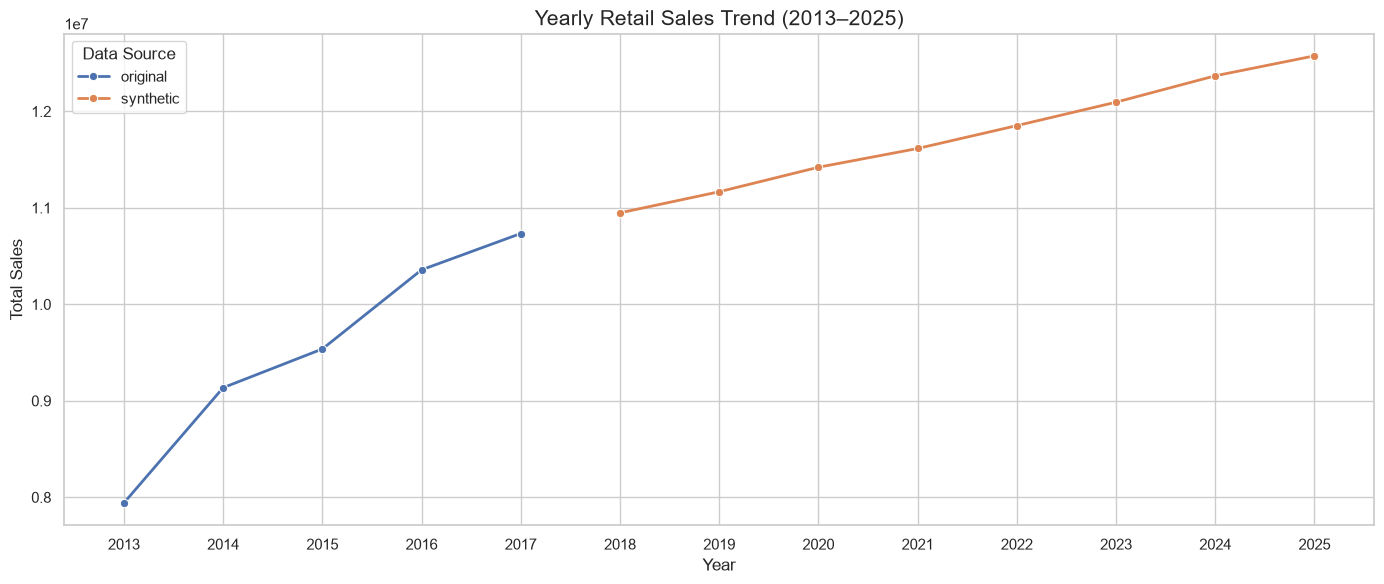

In [2]:
# Extract year from date

df["year"] = df["date"].dt.year

# Calculate yearly sales by data source

yearly_sales = (
    df.groupby(["year", "data_source"], observed=True)["sales"]
      .sum()
      .reset_index()
)

print("YEARLY SALES SUMMARY")
print("-" * 50)

display(yearly_sales)

# Visualize yearly sales trends

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=yearly_sales,
    x="year",
    y="sales",
    hue="data_source",
    marker="o",
    linewidth=2
)

plt.title("Yearly Retail Sales Trend (2013–2025)", fontsize=15)
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(range(2013, 2026))
plt.legend(title="Data Source")

plt.tight_layout()
plt.show()

MONTHLY AVERAGE SALES
--------------------------------------------------


,month,data_source,sales
0,1,original,35.524503
1,1,synthetic,43.664855
2,2,original,39.378397
3,2,synthetic,48.544062
4,3,original,47.305574
5,3,synthetic,58.392653
6,4,original,55.152893
7,4,synthetic,67.869683
8,5,original,59.128219
9,5,synthetic,72.806718


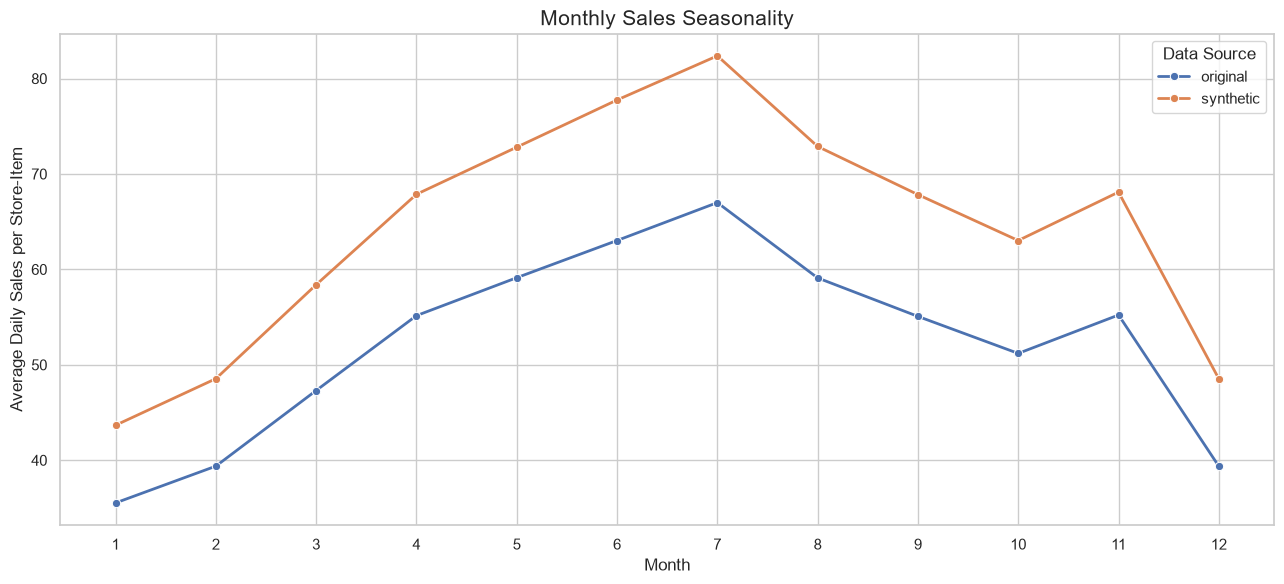

In [3]:
# Extract month from date

df["month"] = df["date"].dt.month

# Calculate average sales by month and data source

monthly_sales = (
    df.groupby(["month", "data_source"], observed=True)["sales"]
      .mean()
      .reset_index()
)

print("MONTHLY AVERAGE SALES")
print("-" * 50)

display(monthly_sales)

# Visualize monthly seasonality

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_sales,
    x="month",
    y="sales",
    hue="data_source",
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Seasonality", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Average Daily Sales per Store-Item")
plt.xticks(range(1, 13))
plt.legend(title="Data Source")

plt.tight_layout()
plt.show()

AVERAGE DAILY STORE PERFORMANCE
--------------------------------------------------


,store,data_source,average_daily_sales
0,1,original,2363.418949
1,1,synthetic,2913.325804
2,2,original,3351.658269
3,2,synthetic,4124.402806
4,3,original,2976.530120
5,3,synthetic,3668.120465
6,4,original,2745.147317
7,4,synthetic,3380.804586
8,5,original,1988.508215
9,5,synthetic,2450.067762


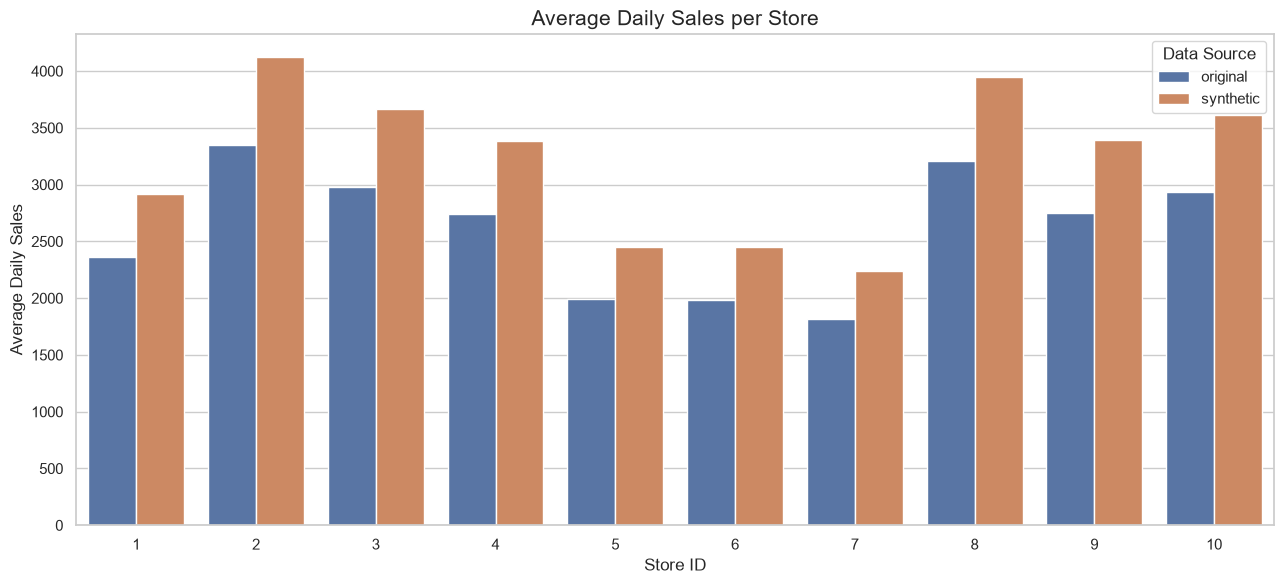

In [4]:
# Calculate average daily sales for each store and data source

store_daily_sales = (
    df.groupby(["date", "store", "data_source"], observed=True)["sales"]
      .sum()
      .reset_index()
)

store_performance = (
    store_daily_sales
    .groupby(["store", "data_source"], observed=True)["sales"]
    .mean()
    .reset_index(name="average_daily_sales")
)

print("AVERAGE DAILY STORE PERFORMANCE")
print("-" * 50)

display(store_performance)

# Visualize store-wise performance

plt.figure(figsize=(13, 6))

sns.barplot(
    data=store_performance,
    x="store",
    y="average_daily_sales",
    hue="data_source"
)

plt.title("Average Daily Sales per Store", fontsize=15)
plt.xlabel("Store ID")
plt.ylabel("Average Daily Sales")
plt.legend(title="Data Source")

plt.tight_layout()
plt.show()

ITEM-WISE AVERAGE SALES
--------------------------------------------------


,item,data_source,average_daily_sales
0,1,original,21.981599
1,1,synthetic,26.947399
2,2,original,58.574151
3,2,synthetic,72.132649
4,3,original,36.642223
5,3,synthetic,45.258214
6,4,original,22.010241
7,4,synthetic,26.910335
8,5,original,18.358708
9,5,synthetic,22.722211



TOP 10 HIGH-DEMAND ITEMS


,item,data_source,average_daily_sales
28,15,original,88.030778
54,28,original,87.881325
24,13,original,84.316594
34,18,original,84.275794
48,25,original,80.686418
88,45,original,80.584173
74,38,original,80.521906
42,22,original,80.502245
70,36,original,77.028916
14,8,original,76.950055


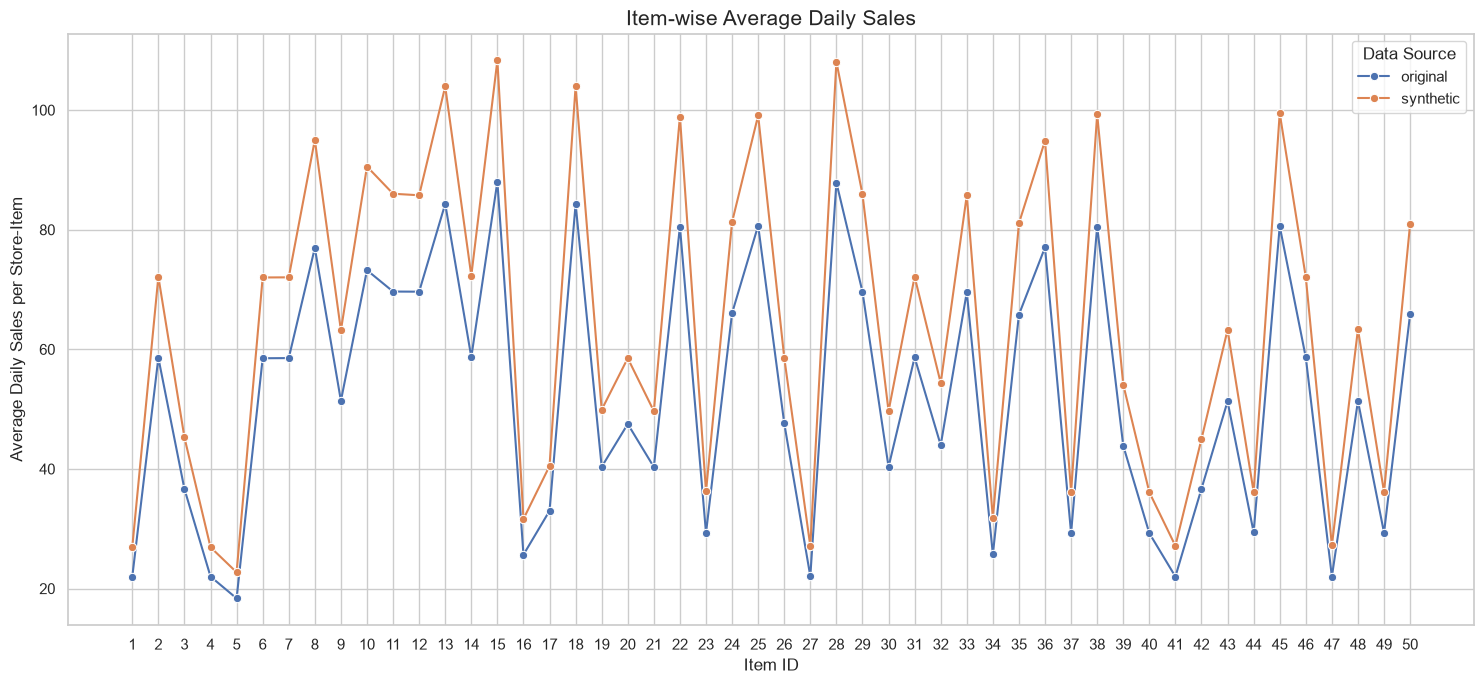

In [5]:
# Calculate average sales for each item and data source

item_sales = (
    df.groupby(["item", "data_source"], observed=True)["sales"]
      .mean()
      .reset_index(name="average_daily_sales")
)

print("ITEM-WISE AVERAGE SALES")
print("-" * 50)

display(item_sales.head(20))

# Identify top 10 items in each data source

top_items = (
    item_sales.sort_values(
        ["data_source", "average_daily_sales"],
        ascending=[True, False]
    )
    .groupby("data_source", observed=True)
    .head(10)
)

print("\nTOP 10 HIGH-DEMAND ITEMS")

display(top_items)

# Visualize item-wise demand

plt.figure(figsize=(15, 7))

sns.lineplot(
    data=item_sales,
    x="item",
    y="average_daily_sales",
    hue="data_source",
    marker="o"
)

plt.title("Item-wise Average Daily Sales", fontsize=15)
plt.xlabel("Item ID")
plt.ylabel("Average Daily Sales per Store-Item")
plt.xticks(range(1, 51))
plt.legend(title="Data Source")

plt.tight_layout()
plt.show()

SALES DISTRIBUTION SUMMARY
--------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
data_source,,,,,,,,
original,913000.0,52.25,28.80,0.0,30.0,47.0,70.0,231.0
synthetic,1461000.0,64.37,34.56,0.0,37.0,58.0,86.0,240.0


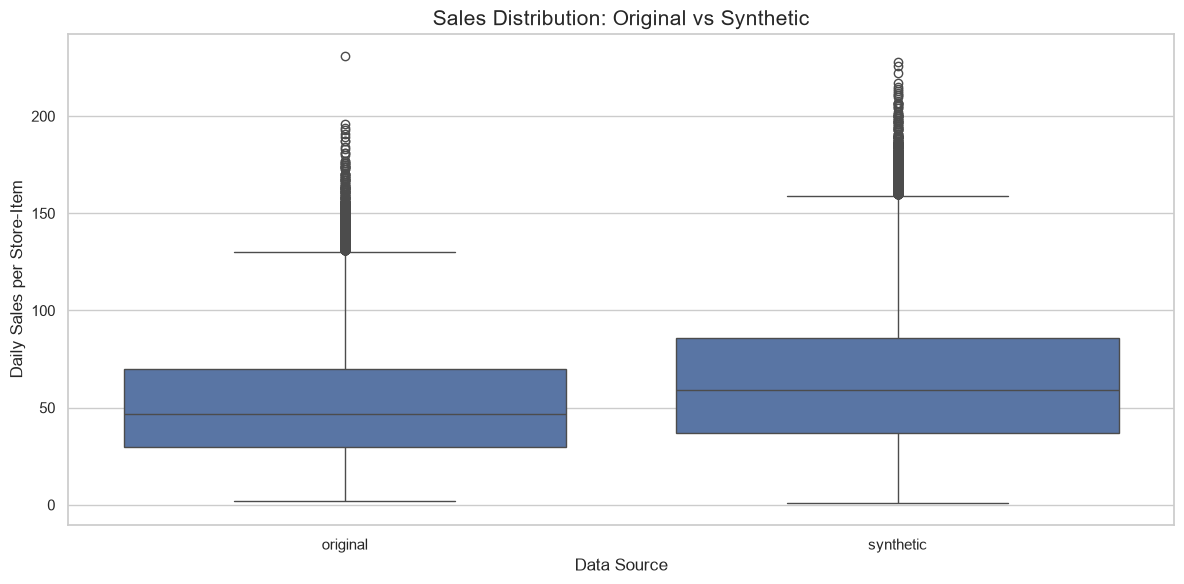

In [6]:
# Calculate sales distribution statistics

print("SALES DISTRIBUTION SUMMARY")
print("-" * 50)

distribution_summary = (
    df.groupby("data_source", observed=True)["sales"]
      .describe()
      .round(2)
)

display(distribution_summary)

# Sample records for faster visualization

plot_data = (
    df.groupby("data_source", observed=True, group_keys=False)
      .sample(n=50000, random_state=42)
)

# Visualize sales distributions

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=plot_data,
    x="data_source",
    y="sales"
)

plt.title("Sales Distribution: Original vs Synthetic", fontsize=15)
plt.xlabel("Data Source")
plt.ylabel("Daily Sales per Store-Item")

plt.tight_layout()
plt.show()

YEAR-OVER-YEAR SALES GROWTH
--------------------------------------------------


,year,total_sales,growth_percentage
0,2013,7941243,NaN
1,2014,9135482,15.04
2,2015,9536887,4.39
3,2016,10357160,8.60
4,2017,10733740,3.64
5,2018,10947805,1.99
6,2019,11166673,2.00
7,2020,11420678,2.27
8,2021,11614976,1.70
9,2022,11852091,2.04


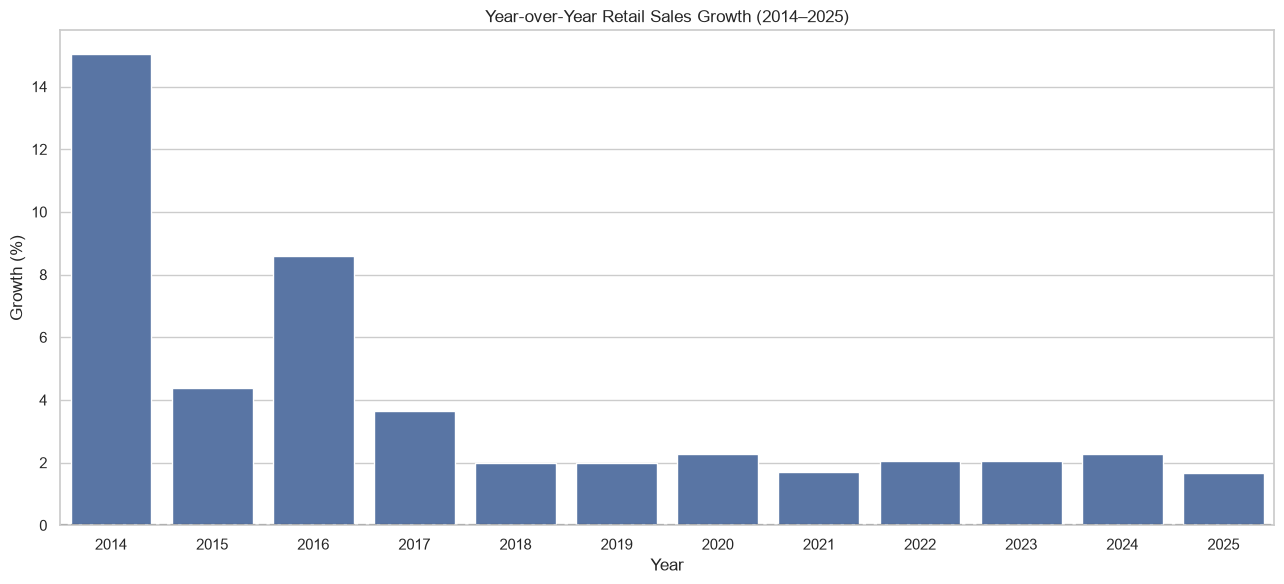

In [8]:
# Calculate total annual sales

yearly_total = (
    df.groupby("year")["sales"]
      .sum()
      .reset_index(name="total_sales")
)

# Calculate year-over-year growth percentage

yearly_total["growth_percentage"] = (
    yearly_total["total_sales"].pct_change() * 100
)

print("YEAR-OVER-YEAR SALES GROWTH")
print("-" * 50)

display(yearly_total.round(2))

# Visualize annual growth rates

plt.figure(figsize=(13, 6))

sns.barplot(
    data=yearly_total.dropna(),
    x="year",
    y="growth_percentage"
)

plt.axhline(0, linestyle="--", color="black")

plt.title("Year-over-Year Retail Sales Growth (2014–2025)")
plt.xlabel("Year")
plt.ylabel("Growth (%)")

plt.tight_layout()
plt.show()

In [9]:
# Compare average sales for each store-item combination

transition_data = df[df["year"].isin([2017, 2018])]

transition_comparison = (
    transition_data
    .groupby(["store", "item", "year"])["sales"]
    .mean()
    .unstack()
)

transition_comparison.columns = ["sales_2017", "sales_2018"]

# Calculate percentage change

transition_comparison["growth_percentage"] = (
    (transition_comparison["sales_2018"] -
     transition_comparison["sales_2017"])
    / transition_comparison["sales_2017"]
) * 100

print("2017 VS 2018 STORE-ITEM COMPARISON")
print("-" * 55)

display(transition_comparison.describe().round(2))

print(
    "\nAVERAGE CHANGE:",
    round(transition_comparison["growth_percentage"].mean(), 2),
    "%"
)

print("\nSTORE-ITEM COMBINATIONS WITH LARGEST DECLINES")

display(
    transition_comparison
    .sort_values("growth_percentage")
    .head(10)
    .round(2)
)

2017 VS 2018 STORE-ITEM COMPARISON
-------------------------------------------------------


,sales_2017,sales_2018,growth_percentage
count,500.00,500.00,500.00
mean,58.82,59.99,2.00
std,27.08,27.62,0.80
min,14.44,14.78,-0.92
25%,35.15,36.48,1.45
50%,56.24,57.59,2.00
75%,78.20,79.59,2.48
max,126.43,129.34,5.21



AVERAGE CHANGE: 2.0 %

STORE-ITEM COMBINATIONS WITH LARGEST DECLINES


,,sales_2017,sales_2018,growth_percentage
store,item,,,
8,5,25.64,25.40,-0.92
6,49,24.92,24.76,-0.63
1,1,22.18,22.06,-0.57
7,16,19.79,19.71,-0.40
6,41,18.43,18.38,-0.27
5,42,31.13,31.08,-0.16
1,16,26.07,26.10,0.11
6,44,25.02,25.07,0.19
1,37,29.60,29.68,0.27
